In [ ]:
import pandas as pd
import numpy as np


In [ ]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/DSA COURSE/Main Projecct/converted.csv")

print("Dataset loaded successfully")
print("Shape:", df.shape)

df.head()

/tmp/ipykernel_1581/717295763.py:3: DtypeWarning: Columns (17) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("/content/drive/MyDrive/DSA COURSE/Main Projecct/converted.csv")


Dataset loaded successfully
Shape: (152400, 26)


,job_idx,date_dir,node_count,submit_time,start_time,end_time,wall_time,queue_time,run_time,node_hour_usage,...,job_mode,gpu_enabled,peak_power,mean_power,user_id,project_id,project_prefix,host_list,node_list,interconnect_exists
0,1,2024-01-17,60,2024-01-15 13:23:57+00:00,2024-01-17 03:33:50+00:00,2024-01-17 05:02:27+00:00,105,137393.0,5317,88.617,...,batch,NaN,100269.0,96672.0,user0001,OHF001,OHF,['frontier02047' 'frontier02144' 'frontier0216...,['x2103c7s7b0n0' 'x2104c5s7b1n0' 'x2104c7s0b1n...,False
1,2,2024-01-17,16,2024-01-17 04:39:48+00:00,2024-01-17 04:40:18+00:00,2024-01-17 05:05:24+00:00,30,30.0,1506,6.693,...,batch,NaN,23969.0,14410.0,user0002,AIU001,AIU,['frontier00099' 'frontier00232' 'frontier0036...,['x2000c6s1b0n0' 'x2001c6s3b1n0' 'x2002c6s3b1n...,False
2,3,2024-01-17,12,2024-01-17 04:04:02+00:00,2024-01-17 04:09:35+00:00,2024-01-17 05:06:39+00:00,60,333.0,3424,11.413,...,batch,NaN,25241.0,14426.0,user0003,TYO001,TYO,['frontier07720' 'frontier07721' 'frontier0772...,['x2501c2s3b1n0' 'x2501c2s4b0n0' 'x2501c2s4b1n...,False
3,4,2024-01-17,2,2024-01-17 03:09:54+00:00,2024-01-17 03:10:18+00:00,2024-01-17 05:10:19+00:00,120,24.0,7201,4.001,...,batch,NaN,1642.0,1602.0,user0004,VNY001,VNY,['frontier04712' 'frontier04713'],['x2300c6s3b1n0' 'x2300c6s4b0n0'],False
4,5,2024-01-17,2048,2024-01-17 00:08:01+00:00,2024-01-17 04:58:24+00:00,2024-01-17 05:16:56+00:00,25,17423.0,1112,632.604,...,batch,NaN,2719996.0,2397333.0,user0005,OHF001,OHF,['frontier00047' 'frontier00048' 'frontier0004...,['x2000c2s7b0n0' 'x2000c2s7b1n0' 'x2000c3s0b0n...,False


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 152400 entries, 0 to 152399
Data columns (total 26 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   job_idx              152400 non-null  int64  
 1   date_dir             152400 non-null  object 
 2   node_count           152400 non-null  int64  
 3   submit_time          152400 non-null  object 
 4   start_time           152400 non-null  object 
 5   end_time             152400 non-null  object 
 6   wall_time            152400 non-null  int64  
 7   queue_time           152399 non-null  float64
 8   run_time             152400 non-null  int64  
 9   node_hour_usage      152400 non-null  float64
 10  completion_state     152400 non-null  object 
 11  exit_code            152400 non-null  object 
 12  derived_exit_code    152400 non-null  object 
 13  init_priority        151396 non-null  float64
 14  final_priority       152400 non-null  int64  
 15  queue            

In [ ]:
# Check dataset structure
print("Dataset Shape:", df.shape)

# Check column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check data types and missing values
print("\nDataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum().sort_values(ascending=False))

# Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Shape: (152400, 26)

Column Names:
['job_idx', 'date_dir', 'node_count', 'submit_time', 'start_time', 'end_time', 'wall_time', 'queue_time', 'run_time', 'node_hour_usage', 'completion_state', 'exit_code', 'derived_exit_code', 'init_priority', 'final_priority', 'queue', 'job_mode', 'gpu_enabled', 'peak_power', 'mean_power', 'user_id', 'project_id', 'project_prefix', 'host_list', 'node_list', 'interconnect_exists']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 152400 entries, 0 to 152399
Data columns (total 26 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   job_idx              152400 non-null  int64  
 1   date_dir             152400 non-null  object 
 2   node_count           152400 non-null  int64  
 3   submit_time          152400 non-null  object 
 4   start_time           152400 non-null  object 
 5   end_time             152400 non-null  object 
 6   wall_time            152400 n

In [ ]:
# Numerical feature analysis
numeric_cols = [
    "node_count",
    "wall_time",
    "queue_time",
    "run_time",
    "node_hour_usage",
    "peak_power",
    "mean_power"
]

display(df[numeric_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
node_count,152400.0,124.716017,6.364758e+02,1.000,1.000,4.000,21.000,9.450000e+03
wall_time,152400.0,99.568504,1.320269e+02,1.000,30.000,119.000,120.000,1.440000e+03
queue_time,152399.0,25168.391558,1.164749e+05,0.000,41.000,1055.000,11391.000,1.033047e+07
run_time,152400.0,4022.559298,6.115908e+03,70.000,682.000,2764.000,6500.000,8.642900e+04
node_hour_usage,152400.0,135.909460,1.196102e+03,0.039,0.667,2.006,16.018,7.524348e+04
peak_power,152400.0,167430.649219,1.024442e+06,309.000,1285.000,5079.500,30916.750,2.769863e+07
mean_power,152400.0,114893.553780,6.288677e+05,301.000,1085.000,3702.000,24590.750,2.201389e+07


In [ ]:
# Sample records
display(
    df[
        [
            "submit_time",
            "start_time",
            "end_time",
            "wall_time",
            "run_time",
            "node_count",
            "mean_power",
            "peak_power"
        ]
    ].sample(10, random_state=42)
)

,submit_time,start_time,end_time,wall_time,run_time,node_count,mean_power,peak_power
68956,2024-11-18 03:17:49+00:00,2024-11-22 22:44:43+00:00,2024-11-23 00:44:46+00:00,120,7203,8,6569.0,6931.0
119474,2025-07-13 02:11:34+00:00,2025-07-13 11:44:50+00:00,2025-07-13 12:05:03+00:00,120,1213,1,548.0,612.0
70950,2024-12-06 17:47:23+00:00,2024-12-06 17:48:14+00:00,2024-12-06 17:58:38+00:00,10,624,1,882.0,911.0
80892,2025-01-29 03:05:02+00:00,2025-01-29 03:05:41+00:00,2025-01-29 03:10:31+00:00,5,290,1,556.0,640.0
151054,2025-12-31 02:05:14+00:00,2025-12-31 02:05:55+00:00,2025-12-31 02:29:52+00:00,120,1437,3,2820.0,4080.0
55532,2024-09-13 01:42:23+00:00,2024-09-13 01:42:54+00:00,2024-09-13 02:12:50+00:00,119,1796,1,2029.0,2423.0
119166,2025-07-09 16:19:42+00:00,2025-07-10 02:05:41+00:00,2025-07-10 03:35:56+00:00,90,5415,1,845.0,1378.0
39257,2024-06-12 02:44:10+00:00,2024-06-12 16:06:45+00:00,2024-06-12 18:06:49+00:00,120,7204,1,652.0,684.0
140166,2025-11-04 20:39:52+00:00,2025-11-05 02:22:37+00:00,2025-11-05 02:52:41+00:00,30,1804,4,6586.0,7508.0
67935,2024-11-22 06:36:09+00:00,2024-11-22 06:37:04+00:00,2024-11-22 06:41:32+00:00,120,268,64,59267.0,147150.0


In [ ]:
# Create electricity consumption target

df["energy_kwh"] = (
    df["mean_power"] * df["run_time"]
) / 3_600_000

# Display the new target
display(
    df[
        ["mean_power", "run_time", "energy_kwh"]
    ].head(10)
)

,mean_power,run_time,energy_kwh
0,96672.0,5317,142.779173
1,14410.0,1506,6.028183
2,14426.0,3424,13.720729
3,1602.0,7201,3.204445
4,2397333.0,1112,740.509527
5,41803.0,4081,47.388345
6,1543.0,180,0.077150
7,7486.0,6538,13.595408
8,668.0,220,0.040822
9,1604.0,519,0.231243


In [ ]:
# Check target quality

print("Missing energy values:",
      df["energy_kwh"].isna().sum())

print("Infinite energy values:",
      (~df["energy_kwh"].map(
          lambda x: abs(x) != float("inf")
      )).sum())

print("Zero or negative energy values:",
      (df["energy_kwh"] <= 0).sum())

print("\nEnergy consumption statistics:")
display(df["energy_kwh"].describe())

Missing energy values: 0
Infinite energy values: 0
Zero or negative energy values: 0

Energy consumption statistics:


,energy_kwh
count,152400.000000
mean,141.414464
std,1314.338755
min,0.018600
25%,0.498752
50%,2.900410
75%,16.794892
max,105005.043000


In [ ]:
df["energy_kwh"].describe()

,energy_kwh
count,152400.000000
mean,141.414464
std,1314.338755
min,0.018600
25%,0.498752
50%,2.900410
75%,16.794892
max,105005.043000


In [ ]:
# Convert submit_time to datetime if it isn't already
df["submit_time"] = pd.to_datetime(df["submit_time"])

# Engineer the missing datetime features
df["submit_hour"] = df["submit_time"].dt.hour
df["submit_dayofweek"] = df["submit_time"].dt.dayofweek
df["submit_month"] = df["submit_time"].dt.month
df["is_weekend"] = df["submit_dayofweek"].isin([5, 6]).astype(int)

# Cyclical features for hour
df["hour_sin"] = np.sin(2 * np.pi * df["submit_hour"] / 24.0)
df["hour_cos"] = np.cos(2 * np.pi * df["submit_hour"] / 24.0)

# Define input features
feature_columns = [
    "node_count",
    "wall_time",
    "queue",
    "job_mode",
    "gpu_enabled",
    "interconnect_exists",
    "submit_hour",
    "submit_dayofweek",
    "submit_month",
    "is_weekend",
    "hour_sin",
    "hour_cos"
]

# Create model dataset
X = df[feature_columns].copy()
y = df["energy_kwh"].copy()

# Handle GPU missing values
X["gpu_enabled"] = (
    X["gpu_enabled"]
    .fillna("Unknown")
    .astype(str)
)

# Verify
print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures:")
display(X.head())

print("\nTarget:")
display(y.head())

Features shape: (152400, 12)
Target shape: (152400,)

Features:


,node_count,wall_time,queue,job_mode,gpu_enabled,interconnect_exists,submit_hour,submit_dayofweek,submit_month,is_weekend,hour_sin,hour_cos
0,60,105,batch-normal,batch,Unknown,False,13,0,1,0,-0.258819,-0.965926
1,16,30,batch-normal,batch,Unknown,False,4,2,1,0,0.866025,0.500000
2,12,60,batch-normal,batch,Unknown,False,4,2,1,0,0.866025,0.500000
3,2,120,batch-normal,batch,Unknown,False,3,2,1,0,0.707107,0.707107
4,2048,25,batch-normal,batch,Unknown,False,0,2,1,0,0.000000,1.000000



Target:


,energy_kwh
0,142.779173
1,6.028183
2,13.720729
3,3.204445
4,740.509527


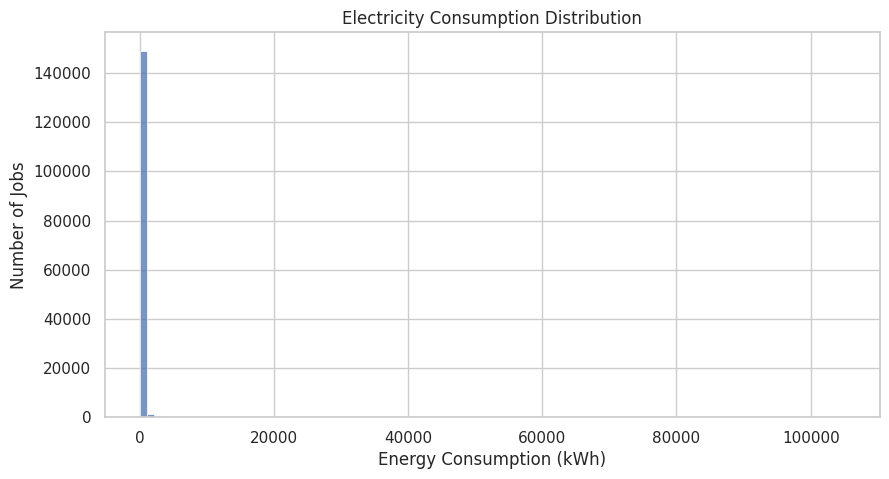

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="energy_kwh",
    bins=100
)

plt.title("Electricity Consumption Distribution")
plt.xlabel("Energy Consumption (kWh)")
plt.ylabel("Number of Jobs")

plt.show()

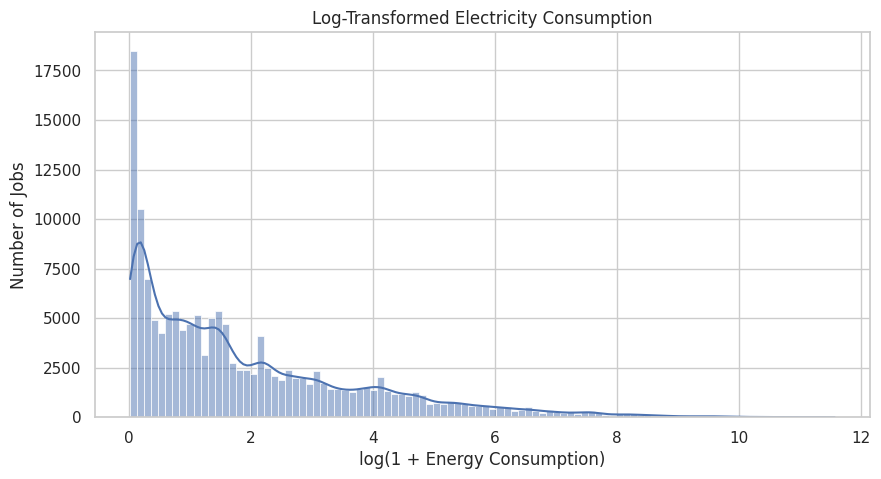

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    np.log1p(df["energy_kwh"]),
    bins=100,
    kde=True
)

plt.title("Log-Transformed Electricity Consumption")
plt.xlabel("log(1 + Energy Consumption)")
plt.ylabel("Number of Jobs")

plt.show()

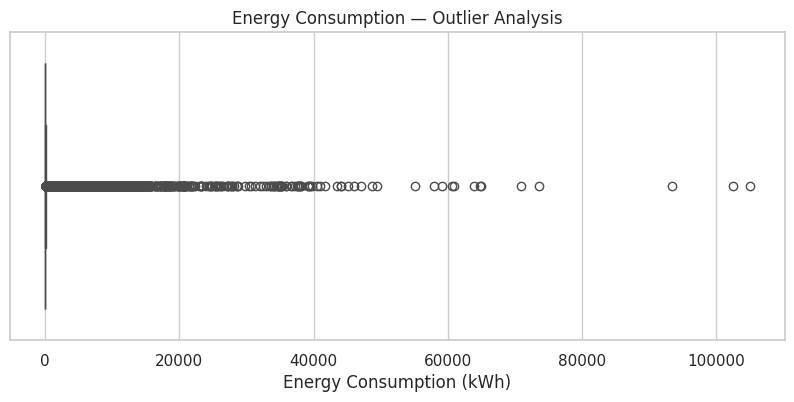

In [ ]:
plt.figure(figsize=(10, 4))

sns.boxplot(
    x=df["energy_kwh"]
)

plt.title("Energy Consumption — Outlier Analysis")
plt.xlabel("Energy Consumption (kWh)")

plt.show()

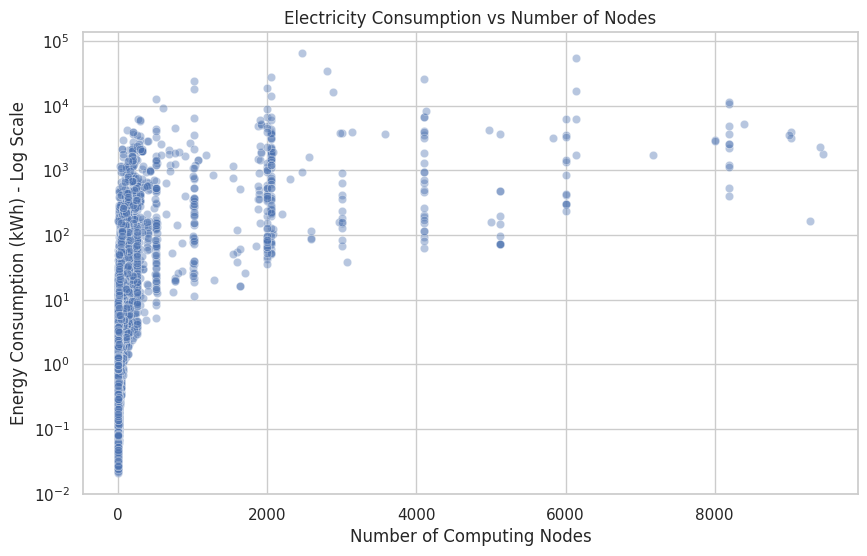

In [ ]:
# Sample records for visualization
plot_df = df.sample(
    n=10000,
    random_state=42
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=plot_df,
    x="node_count",
    y="energy_kwh",
    alpha=0.4
)

plt.yscale("log")

plt.title("Electricity Consumption vs Number of Nodes")
plt.xlabel("Number of Computing Nodes")
plt.ylabel("Energy Consumption (kWh) - Log Scale")

plt.show()

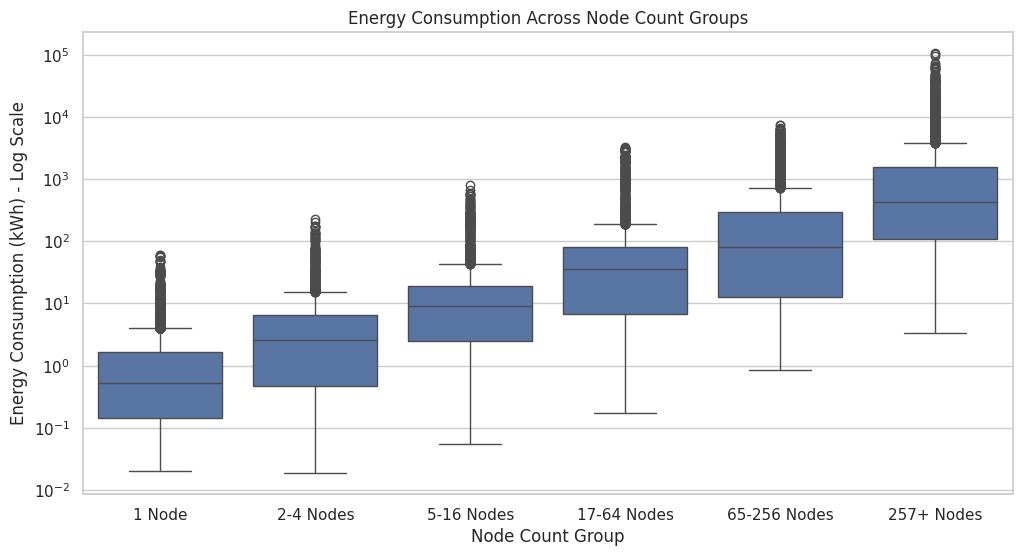

In [ ]:
# Create node-count groups
df["node_group"] = pd.cut(
    df["node_count"],
    bins=[0, 1, 4, 16, 64, 256, float("inf")],
    labels=[
        "1 Node",
        "2-4 Nodes",
        "5-16 Nodes",
        "17-64 Nodes",
        "65-256 Nodes",
        "257+ Nodes"
    ]
)

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="node_group",
    y="energy_kwh"
)

plt.yscale("log")

plt.title("Energy Consumption Across Node Count Groups")
plt.xlabel("Node Count Group")
plt.ylabel("Energy Consumption (kWh) - Log Scale")

plt.show()

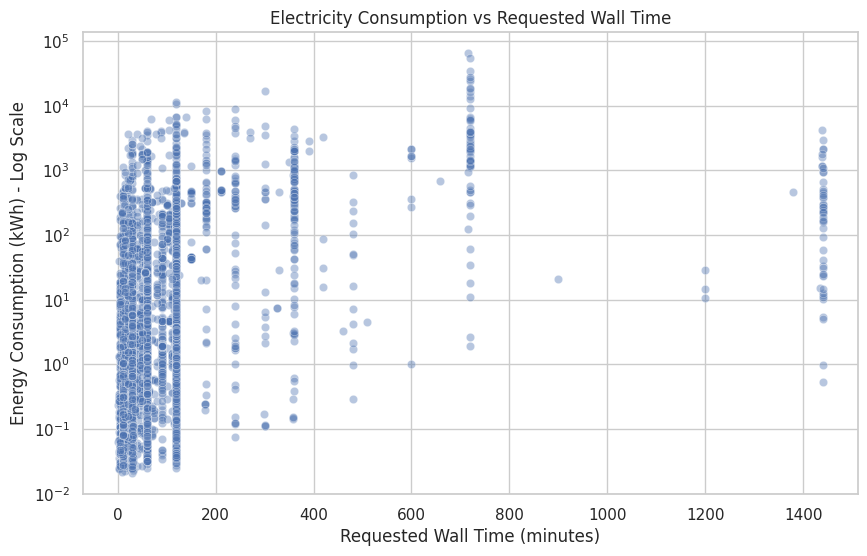

In [ ]:
# Sample for visualization
plot_df = df.sample(
    n=10000,
    random_state=42
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=plot_df,
    x="wall_time",
    y="energy_kwh",
    alpha=0.4
)

plt.yscale("log")

plt.title("Electricity Consumption vs Requested Wall Time")
plt.xlabel("Requested Wall Time (minutes)")
plt.ylabel("Energy Consumption (kWh) - Log Scale")

plt.show()

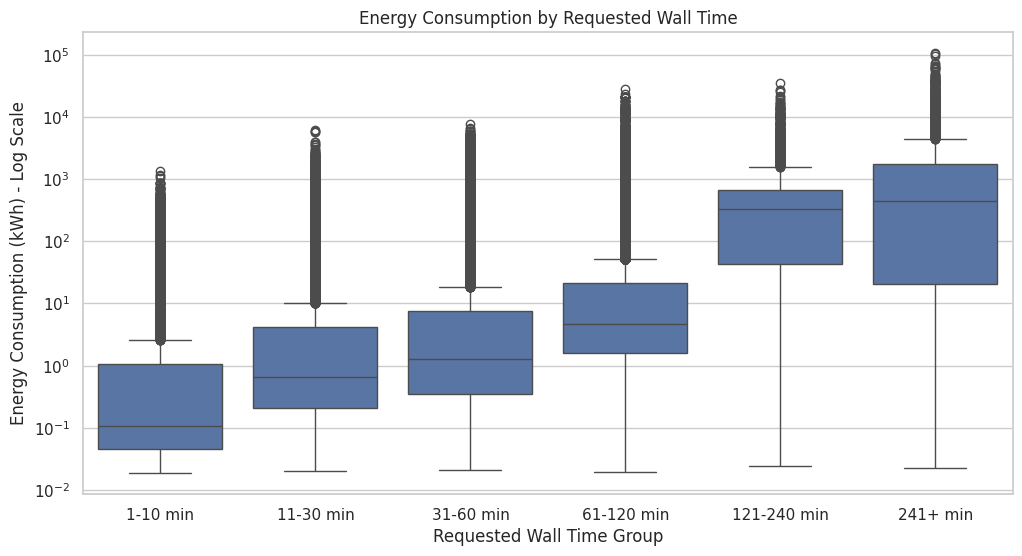

In [ ]:
# Create wall-time groups
df["wall_time_group"] = pd.cut(
    df["wall_time"],
    bins=[0, 10, 30, 60, 120, 240, 1440],
    labels=[
        "1-10 min",
        "11-30 min",
        "31-60 min",
        "61-120 min",
        "121-240 min",
        "241+ min"
    ],
    include_lowest=True
)

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="wall_time_group",
    y="energy_kwh"
)

plt.yscale("log")

plt.title("Energy Consumption by Requested Wall Time")
plt.xlabel("Requested Wall Time Group")
plt.ylabel("Energy Consumption (kWh) - Log Scale")

plt.show()

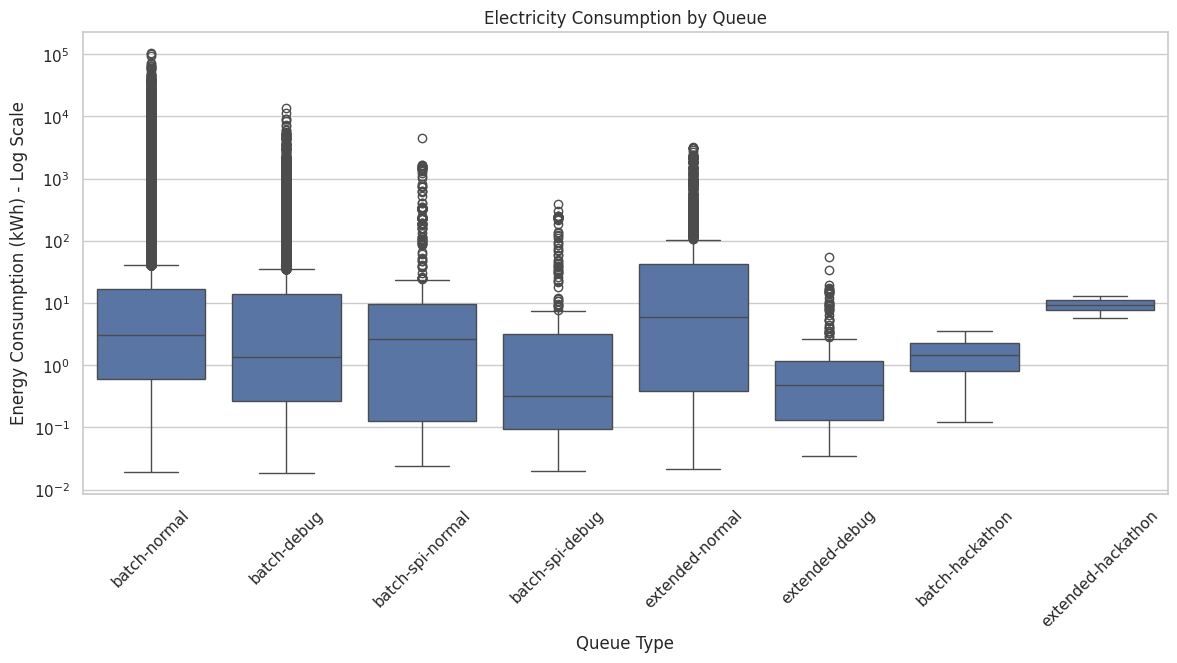

In [ ]:
plt.figure(figsize=(14, 6))

sns.boxplot(
    data=df,
    x="queue",
    y="energy_kwh"
)

plt.yscale("log")

plt.title("Electricity Consumption by Queue")
plt.xlabel("Queue Type")
plt.ylabel("Energy Consumption (kWh) - Log Scale")

plt.xticks(rotation=45)

plt.show()

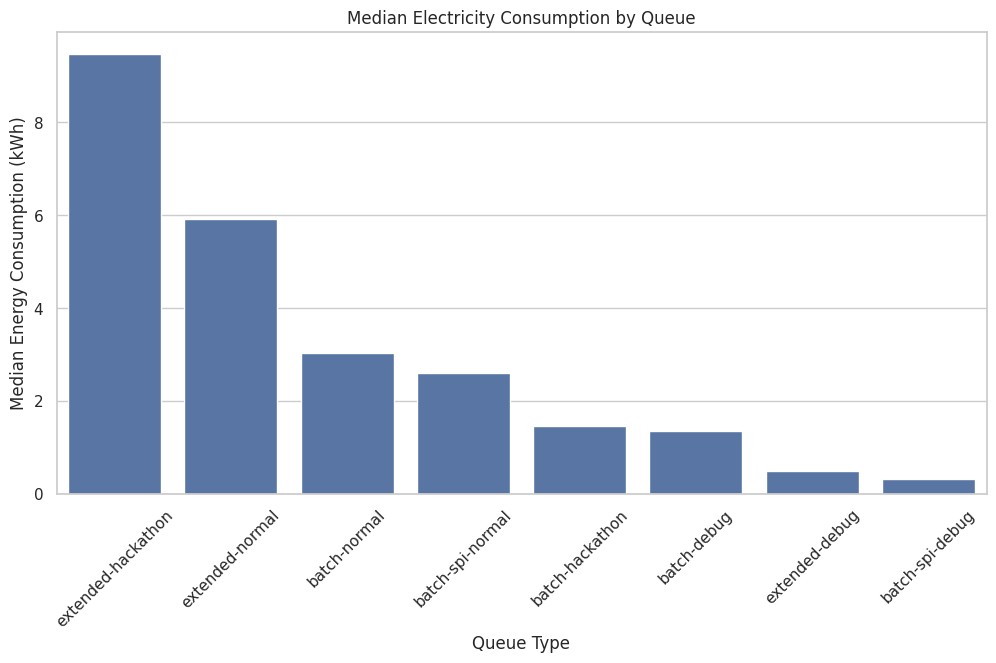

In [ ]:
queue_energy = (
    df.groupby("queue", observed=True)["energy_kwh"]
    .median()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=queue_energy.index,
    y=queue_energy.values
)

plt.title("Median Electricity Consumption by Queue")
plt.xlabel("Queue Type")
plt.ylabel("Median Energy Consumption (kWh)")

plt.xticks(rotation=45)

plt.show()

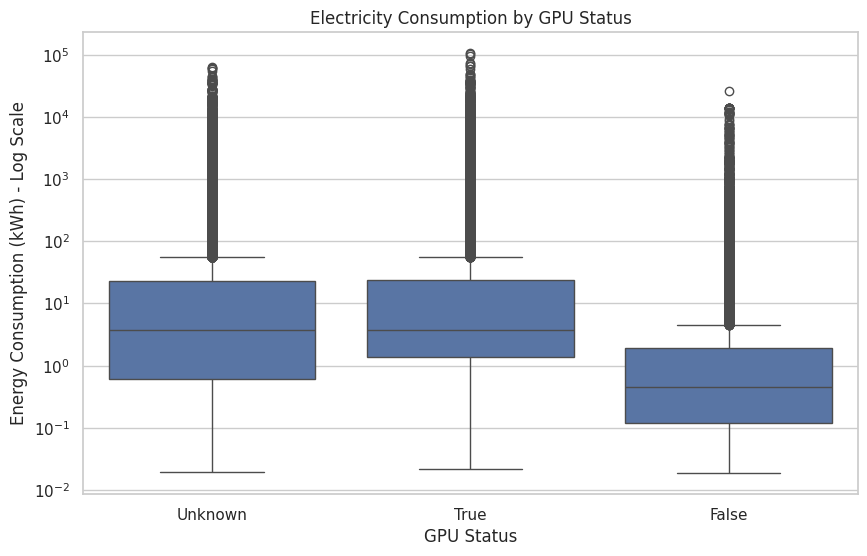

In [ ]:
# Create a visualization-only GPU status column
gpu_plot_df = df.copy()

gpu_plot_df["gpu_status"] = (
    gpu_plot_df["gpu_enabled"]
    .fillna("Unknown")
    .astype(str)
)

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=gpu_plot_df,
    x="gpu_status",
    y="energy_kwh"
)

plt.yscale("log")

plt.title("Electricity Consumption by GPU Status")
plt.xlabel("GPU Status")
plt.ylabel("Energy Consumption (kWh) - Log Scale")

plt.show()

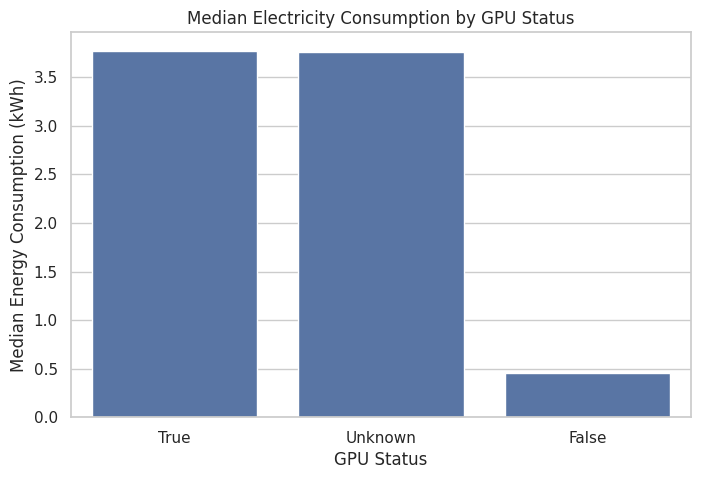

In [ ]:
gpu_median_energy = (
    gpu_plot_df.groupby("gpu_status")["energy_kwh"]
    .median()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=gpu_median_energy.index,
    y=gpu_median_energy.values
)

plt.title("Median Electricity Consumption by GPU Status")
plt.xlabel("GPU Status")
plt.ylabel("Median Energy Consumption (kWh)")

plt.show()

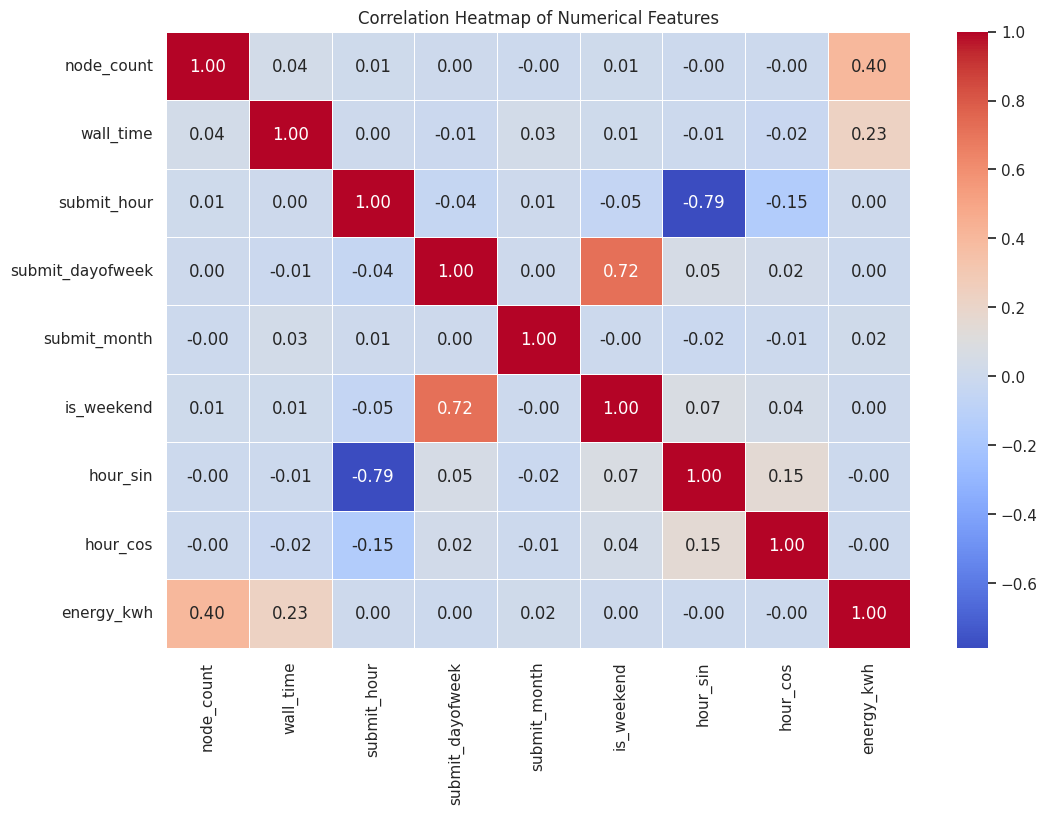

In [ ]:
# Select numerical features
numeric_features = [
    "node_count",
    "wall_time",
    "submit_hour",
    "submit_dayofweek",
    "submit_month",
    "is_weekend",
    "hour_sin",
    "hour_cos",
    "energy_kwh"
]

# Calculate correlation matrix
correlation_matrix = df[numeric_features].corr()

# Plot heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")
plt.show()